# ЛР1 (доп.): регрессия временного ряда

**Ряд:** `RSXFSN` — Advance Retail Sales: Retail Trade (FRED).  
**Источник:** https://fred.stlouisfed.org/series/RSXFSN  
**Цель:** прогнозировать объём розничных продаж на один месяц вперёд, сведя задачу к регрессии, и построить рекурсивный прогноз на горизонт **H = 12** месяцев.

Датасет хранится локально в `RSXFSN.csv`; значения имеют месячную частоту и сезонную корректировку в исходном ряду не предполагаем.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.seasonal import STL

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.titlesize'] = 13
RANDOM_STATE = 42
H = 12
TEST_MONTHS = 36
DATA_PATH = Path('RSXFSN.csv')


## 1. Загрузка и первичный анализ

Столбец даты приводится к `datetime`, наблюдения сортируются по времени. Пропуски и дубликаты проверяются до построения модели.

In [2]:
raw = pd.read_csv(DATA_PATH)
df = (raw.rename(columns={'observation_date': 'date', 'RSXFSN': 'y'})
        .assign(date=lambda x: pd.to_datetime(x['date']),
                y=lambda x: pd.to_numeric(x['y'], errors='coerce'))
        .dropna(subset=['date', 'y'])
        .drop_duplicates(subset='date')
        .sort_values('date')
        .reset_index(drop=True))

print(f'Наблюдений: {len(df)}')
print(f'Период: {df.date.min():%Y-%m} — {df.date.max():%Y-%m}')
print(f'Пропусков в y: {df.y.isna().sum()}')
print(f'Частота: {pd.infer_freq(df.date)}')
display(df.head())
display(df.tail())


Наблюдений: 416
Период: 1992-01 — 2026-08
Пропусков в y: 0
Частота: MS


,date,y
0,1992-01-01,126717
1,1992-02-01,127022
2,1992-03-01,137978
3,1992-04-01,142314
4,1992-05-01,147550


,date,y
411,2026-04-01,633425
412,2026-05-01,664214
413,2026-06-01,649437
414,2026-07-01,655810
415,2026-08-01,654831


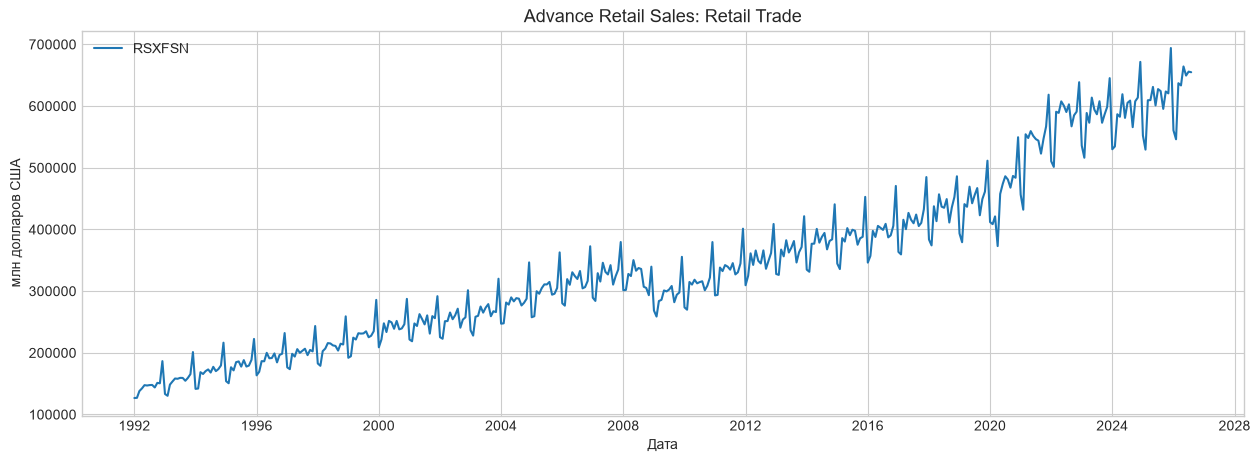

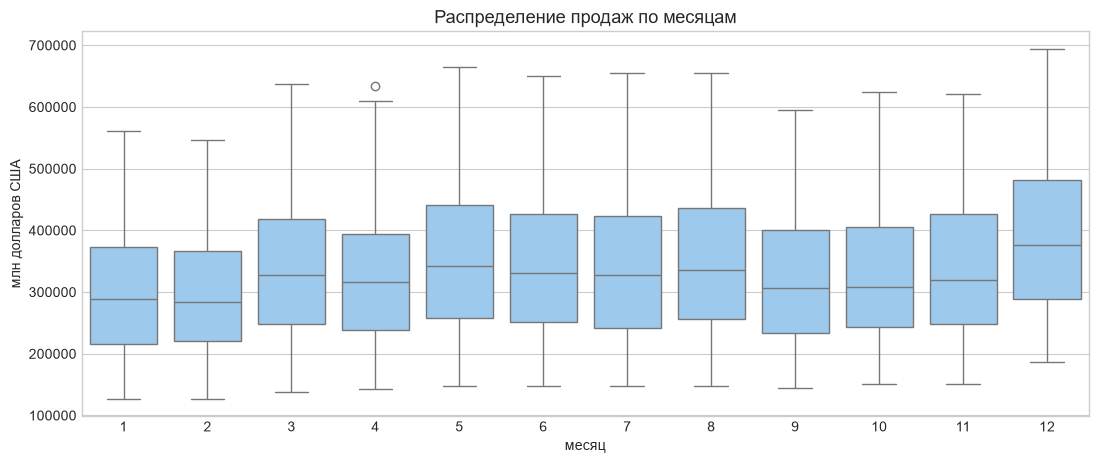

In [3]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df['date'], df['y'], color='#1f77b4', lw=1.5, label='RSXFSN')
ax.set(title='Advance Retail Sales: Retail Trade', xlabel='Дата', ylabel='млн долларов США')
ax.legend()
plt.show()

# Сезонный профиль: распределение значений по месяцам.
tmp = df.assign(month=df.date.dt.month)
fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=tmp, x='month', y='y', color='#90caf9', ax=ax)
ax.set(title='Распределение продаж по месяцам', xlabel='месяц', ylabel='млн долларов США')
plt.show()


Потенциальных выбросов по IQR: 72


,date,y,deviation_from_12m_median
11,1992-12-01,186520,38354.5
23,1993-12-01,201200,41877.0
35,1994-12-01,216404,43106.5
47,1995-12-01,222474,36313.5
59,1996-12-01,232014,36801.5
...,...,...,...
396,2025-01-01,552246,-56035.0
397,2025-02-01,529394,-79751.5
407,2025-12-01,694088,70145.5
408,2026-01-01,560686,-65204.0


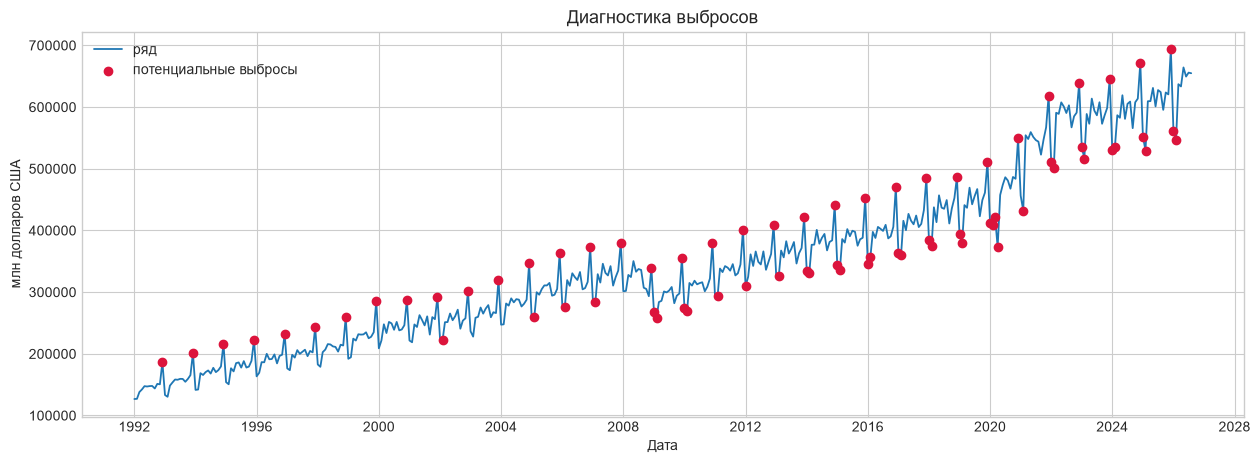

In [4]:
# Диагностика выбросов: отклонение от центрированной 12-месячной медианы.
# Центрирование допустимо только для разведочного анализа, этот признак НЕ используется в модели.
diag = df.copy()
diag['deviation_from_12m_median'] = diag['y'] - diag['y'].rolling(12, center=True, min_periods=6).median()
q1, q3 = diag['deviation_from_12m_median'].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = diag[diag['deviation_from_12m_median'].lt(lower) | diag['deviation_from_12m_median'].gt(upper)]

print(f'Потенциальных выбросов по IQR: {len(outliers)}')
display(outliers[['date', 'y', 'deviation_from_12m_median']].round(1))

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df.date, df.y, label='ряд', lw=1.3)
ax.scatter(outliers.date, outliers.y, color='crimson', zorder=3, label='потенциальные выбросы')
ax.set(title='Диагностика выбросов', xlabel='Дата', ylabel='млн долларов США')
ax.legend()
plt.show()


**Первичный вывод.** На длинном интервале виден восходящий тренд; диаграмма по месяцам показывает годовую (12-месячную) сезонность. Суточную и недельную сезонность оценить нельзя: ряд месячный. Резкие провалы/скачки, в частности около кризисных периодов, отмечаются диагностикой как возможные выбросы; их не удаляем, потому что они отражают реальные изменения спроса.

## 2. Признаки без утечки

Для месяца $t$ каждая числовая характеристика строится **только из `history = y[:t]`**. Поэтому в таблице лаги, сезонный лаг и скользящие статистики сдвинуты в прошлое.

Календарные признаки: месяц, квартал, год и циклическое представление месяца. Признаки дня недели, часа, выходного и праздника неприменимы к данным с месячной частотой.

In [5]:
LAGS = [1, 2, 3, 6, 12]
ROLL_WINDOWS = [3, 6, 12]

def feature_row(history, date, seasonal_profile=None, include_components=False):
    """Строит признаки для date только по наблюдениям, доступным до date."""
    history = np.asarray(history, dtype=float)
    if len(history) < max(LAGS):
        raise ValueError('Недостаточно истории для лагов')

    row = {
        'month': date.month,
        'quarter': date.quarter,
        'year': date.year,
        'month_sin': np.sin(2 * np.pi * date.month / 12),
        'month_cos': np.cos(2 * np.pi * date.month / 12),
    }
    for lag in LAGS:
        row[f'lag_{lag}'] = history[-lag]
    for window in ROLL_WINDOWS:
        values = history[-window:]
        row[f'roll_mean_{window}'] = values.mean()
        row[f'roll_median_{window}'] = np.median(values)
        row[f'roll_std_{window}'] = values.std(ddof=0)
        row[f'roll_min_{window}'] = values.min()
        row[f'roll_max_{window}'] = values.max()

    # Сезонный лаг: значение того же месяца прошлого года.
    row['seasonal_lag_12'] = history[-12]

    if include_components:
        # Оценка тренда доступна в момент прогноза: среднее только прошлых 12 месяцев.
        trend_proxy = history[-12:].mean()
        row['trend_proxy_12'] = trend_proxy
        row['resid_lag1_proxy'] = history[-1] - trend_proxy
        # Профиль сезонности заранее оценивается только на train (см. ниже).
        row['stl_seasonal_profile'] = seasonal_profile.loc[date.month]
    return row


def make_supervised(values, dates, seasonal_profile=None, include_components=False):
    rows, targets, target_dates = [], [], []
    for i in range(max(LAGS), len(values)):
        rows.append(feature_row(values[:i], dates.iloc[i], seasonal_profile, include_components))
        targets.append(values[i])
        target_dates.append(dates.iloc[i])
    return pd.DataFrame(rows, index=pd.DatetimeIndex(target_dates, name='date')), np.asarray(targets)


y_all = df['y'].to_numpy(dtype=float)
dates = df['date']
X_base_all, y_supervised = make_supervised(y_all, dates)
print(f'Размер матрицы признаков: {X_base_all.shape}')
display(X_base_all.head().round(2))


Размер матрицы признаков: (404, 26)


,month,quarter,year,month_sin,month_cos,lag_1,lag_2,lag_3,lag_6,lag_12,...,roll_median_6,roll_std_6,roll_min_6,roll_max_6,roll_mean_12,roll_median_12,roll_std_12,roll_min_12,roll_max_12,seasonal_lag_12
date,,,,,,,,,,,,,,,,,,,,,
1993-01-01,1,1,1993,0.50,0.87,186520.0,150571.0,151260.0,147657.0,126717.0,...,149236.0,14467.33,143808.0,186520.0,146357.42,147270.5,14472.35,126717.0,186520.0,126717.0
1993-02-01,2,1,1993,0.87,0.50,133217.0,186520.0,150571.0,147901.0,127022.0,...,149236.0,16485.65,133217.0,186520.0,146899.08,147270.5,13834.71,127022.0,186520.0,127022.0
1993-03-01,3,1,1993,1.00,0.00,130321.0,133217.0,186520.0,143808.0,137978.0,...,147189.5,18438.24,130321.0,186520.0,147174.00,147270.5,13464.82,130321.0,186520.0,137978.0
1993-04-01,4,2,1993,0.87,-0.50,148430.0,130321.0,133217.0,151260.0,142314.0,...,149500.5,18289.36,130321.0,186520.0,148045.00,147603.5,13176.76,130321.0,186520.0,142314.0
1993-05-01,5,2,1993,0.50,-0.87,153623.0,148430.0,130321.0,150571.0,147550.0,...,149500.5,18336.49,130321.0,186520.0,148987.42,147779.0,13137.53,130321.0,186520.0,147550.0


## 3. Временное разделение и кросс-валидация

Последние 36 месяцев оставлены как финальный тест. Все ранние месяцы образуют train. Для подбора стабильности используем `TimeSeriesSplit` с расширяющимся окном: валидационный отрезок всегда расположен позже обучающего.

Train: 1993-01 — 2023-08, n=368
Test : 2023-09 — 2026-08, n=36


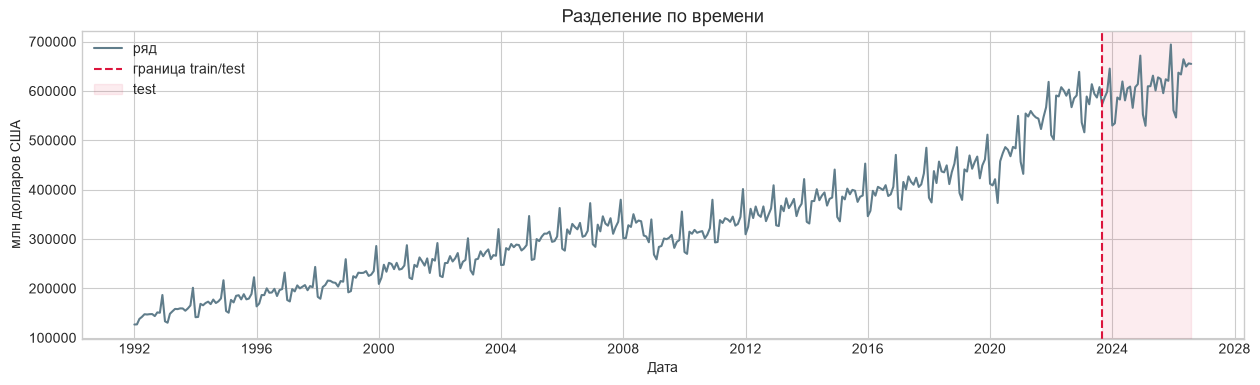

In [6]:
split_date = df['date'].iloc[-TEST_MONTHS]
train_mask = X_base_all.index < split_date
X_train_base, X_test_base = X_base_all.loc[train_mask], X_base_all.loc[~train_mask]
y_train, y_test = y_supervised[train_mask], y_supervised[~train_mask]

print(f'Train: {X_train_base.index.min():%Y-%m} — {X_train_base.index.max():%Y-%m}, n={len(X_train_base)}')
print(f'Test : {X_test_base.index.min():%Y-%m} — {X_test_base.index.max():%Y-%m}, n={len(X_test_base)}')

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(df.date, df.y, color='#607d8b', label='ряд')
ax.axvline(split_date, color='crimson', ls='--', label='граница train/test')
ax.axvspan(split_date, df.date.iloc[-1], color='crimson', alpha=.08, label='test')
ax.set(title='Разделение по времени', xlabel='Дата', ylabel='млн долларов США')
ax.legend()
plt.show()


In [7]:
def make_model(alpha=20.0):
    return Pipeline([
        ('scale', StandardScaler()),
        ('ridge', Ridge(alpha=alpha)),
    ])

def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    nonzero = np.abs(y_true) > 1e-12
    return {
        'MSE': mean_squared_error(y_true, y_pred),
        'MAE': mean_absolute_error(y_true, y_pred),
        'MAPE, %': np.mean(np.abs((y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero])) * 100,
        'WAPE, %': np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true)) * 100,
    }


# One-step CV: признаки в validation используют только предыдущие фактические месяцы.
tscv = TimeSeriesSplit(n_splits=5, test_size=12)
cv_rows = []
for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train_base), start=1):
    fold_model = make_model().fit(X_train_base.iloc[tr_idx], y_train[tr_idx])
    pred = fold_model.predict(X_train_base.iloc[val_idx])
    cv_rows.append({'fold': fold,
                    'train_end': X_train_base.index[tr_idx[-1]].strftime('%Y-%m'),
                    'valid_start': X_train_base.index[val_idx[0]].strftime('%Y-%m'),
                    'valid_end': X_train_base.index[val_idx[-1]].strftime('%Y-%m'),
                    **metrics(y_train[val_idx], pred)})

cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(2))
display(cv_results[['MSE', 'MAE', 'MAPE, %', 'WAPE, %']].mean().to_frame('Среднее по CV').T.round(2))


,fold,train_end,valid_start,valid_end,MSE,MAE,"MAPE, %","WAPE, %"
0,1,2018-08,2018-09,2019-08,1.586449e+08,11338.05,2.62,2.58
1,2,2019-08,2019-09,2020-08,8.235200e+08,20541.51,4.74,4.60
2,3,2020-08,2020-09,2021-08,1.963604e+09,34204.52,6.37,6.64
3,4,2021-08,2021-09,2022-08,5.476726e+08,20264.90,3.47,3.55
4,5,2022-08,2022-09,2023-08,1.938044e+08,11424.55,2.00,1.96


,MSE,MAE,"MAPE, %","WAPE, %"
Среднее по CV,7.374491e+08,19554.7,3.84,3.87


## 4. Модель и рекурсивный прогноз

Модель — `Ridge` после стандартизации признаков. Она обучается на задаче «следующий месяц». Для горизонта $H=12$ использована **рекурсивная стратегия**: после первого прогноза он добавляется в историю и служит лагом для следующего шага.

Тест разбивается на три независимых 12-месячных прогноза: в начале каждого блока доступны только наблюдения до начала этого блока. Это позволяет оценить именно 12-шаговый сценарий на всех 36 тестовых месяцах.

In [8]:
def recursive_block_forecast(model, history, future_dates, columns, seasonal_profile=None, include_components=False):
    """Рекурсивный прогноз: y_hat_t записывается в историю для шага t+1."""
    history = list(np.asarray(history, dtype=float))
    predictions = []
    for date in future_dates:
        row = feature_row(history, pd.Timestamp(date), seasonal_profile, include_components)
        prediction = float(model.predict(pd.DataFrame([row])[columns])[0])
        predictions.append(prediction)
        history.append(prediction)
    return np.asarray(predictions)


def block_predictions(model, columns, seasonal_profile=None, include_components=False):
    test_start_pos = len(df) - TEST_MONTHS
    predictions = []
    for start in range(0, TEST_MONTHS, H):
        stop = min(start + H, TEST_MONTHS)
        origin = test_start_pos + start
        block_dates = df['date'].iloc[origin: origin + (stop - start)]
        predictions.extend(recursive_block_forecast(
            model, y_all[:origin], block_dates, columns, seasonal_profile, include_components
        ))
    return np.asarray(predictions)


base_model = make_model().fit(X_train_base, y_train)
base_train_pred = base_model.predict(X_train_base)
base_test_pred = block_predictions(base_model, X_train_base.columns)


## 5. STL-декомпозиция и признаки компонент

Декомпозиция выполняется для визуального анализа на всём ряду с периодом 12. При построении прогнозных признаков не используем её значения из будущего: сезонный профиль рассчитывается **только по train**, а тренд — как доступное в момент прогноза среднее прошлых 12 месяцев. Это предотвращает утечку из test.

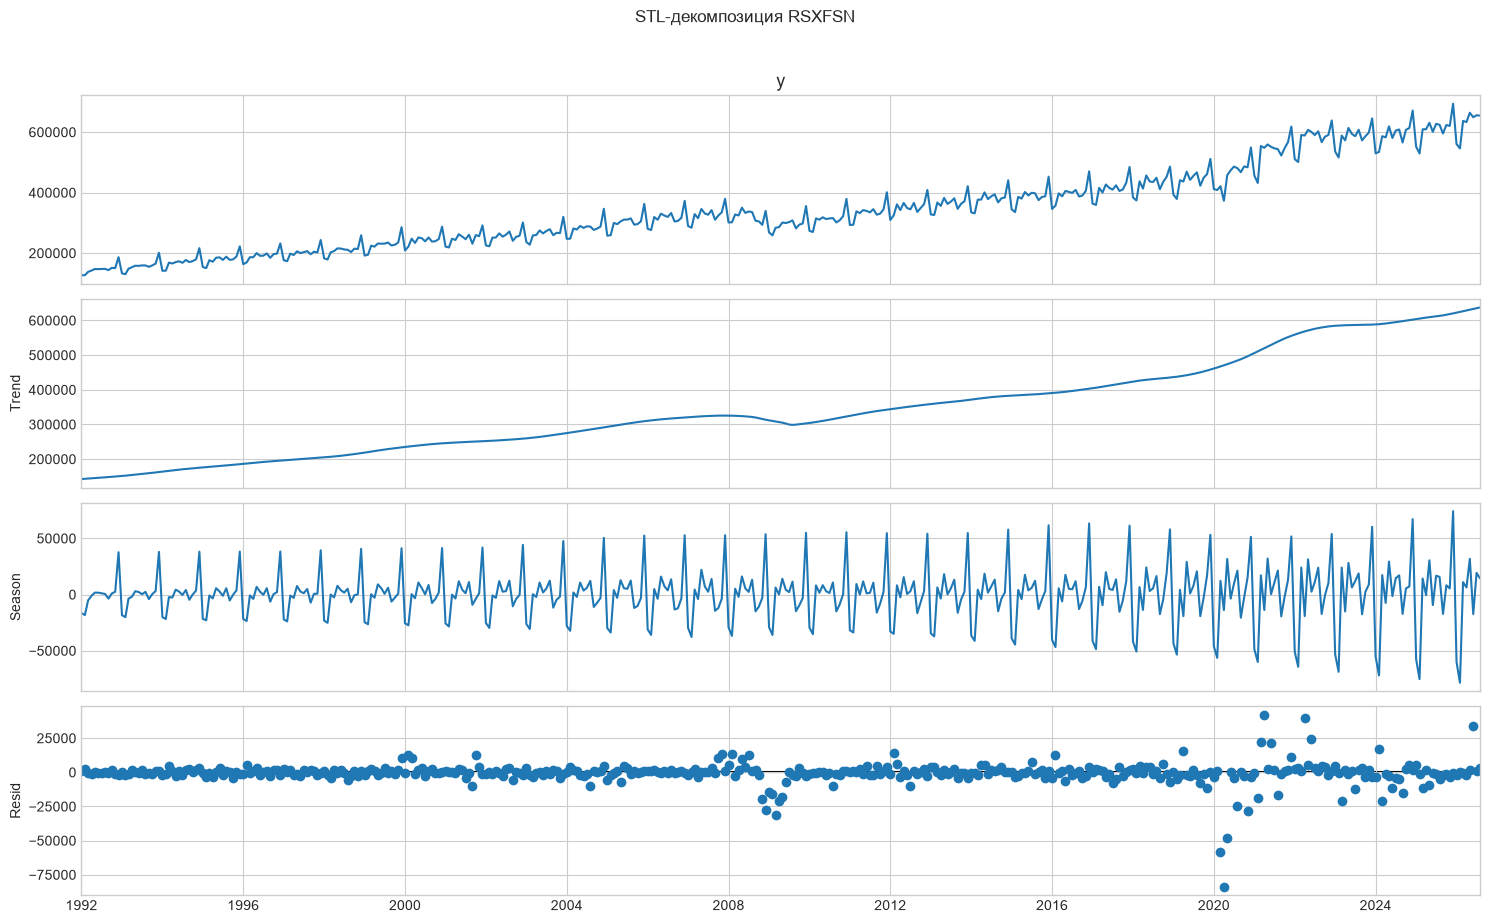

,Средняя STL-сезонность (train)
date,
1,-31310.0
2,-36947.3
3,5574.9
4,-5422.0
5,14300.5
6,2977.1
7,2361.7
8,10410.0
9,-11435.3


In [9]:
stl_full = STL(df.set_index('date')['y'], period=12, robust=True).fit()
fig = stl_full.plot()
fig.set_size_inches(15, 9)
fig.suptitle('STL-декомпозиция RSXFSN', y=1.02)
plt.tight_layout()
plt.show()

# Профиль сезонной компоненты вычислен исключительно на train.
train_series = df.loc[df.date < split_date].set_index('date')['y']
stl_train = STL(train_series, period=12, robust=True).fit()
seasonal_profile = pd.Series(stl_train.seasonal, index=train_series.index).groupby(lambda x: x.month).mean()
seasonal_profile = seasonal_profile.reindex(range(1, 13))
display(seasonal_profile.rename('Средняя STL-сезонность (train)').round(1).to_frame())


In [10]:
# Усиленный набор: сезонная компонента STL (профиль train) + причинные прокси тренда и остатка.
X_enhanced_all, y_enhanced = make_supervised(
    y_all, dates, seasonal_profile=seasonal_profile, include_components=True
)
assert np.array_equal(y_supervised, y_enhanced)
X_train_enhanced = X_enhanced_all.loc[train_mask]

enhanced_model = make_model().fit(X_train_enhanced, y_train)
enhanced_train_pred = enhanced_model.predict(X_train_enhanced)
enhanced_test_pred = block_predictions(
    enhanced_model, X_train_enhanced.columns,
    seasonal_profile=seasonal_profile, include_components=True
)

metric_rows = []
for name, actual, predicted in [
    ('Базовая, train (in-sample, 1 шаг)', y_train, base_train_pred),
    ('Базовая, test (H=12, рекурсивно)', y_test, base_test_pred),
    ('STL-признаки, train (in-sample, 1 шаг)', y_train, enhanced_train_pred),
    ('STL-признаки, test (H=12, рекурсивно)', y_test, enhanced_test_pred),
]:
    metric_rows.append({'Выборка / модель': name, **metrics(actual, predicted)})

metric_table = pd.DataFrame(metric_rows).set_index('Выборка / модель')
display(metric_table.round(2))


,MSE,MAE,"MAPE, %","WAPE, %"
Выборка / модель,,,,
"Базовая, train (in-sample, 1 шаг)",1.562596e+08,8676.58,2.67,2.67
"Базовая, test (H=12, рекурсивно)",9.396640e+08,25107.56,4.04,4.14
"STL-признаки, train (in-sample, 1 шаг)",1.051638e+08,7282.88,2.36,2.24
"STL-признаки, test (H=12, рекурсивно)",1.135073e+09,26866.77,4.29,4.43


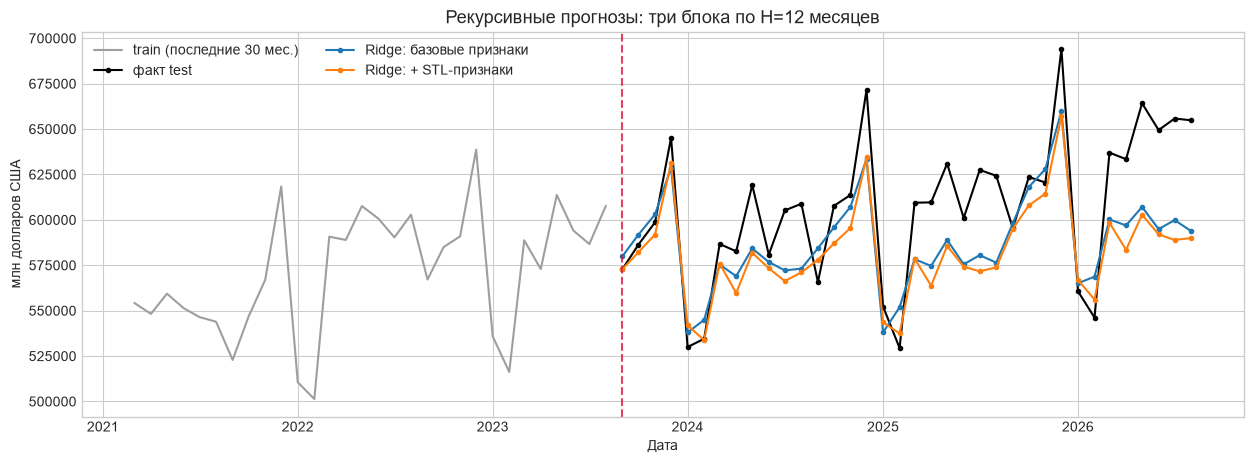

,date,actual,base_recursive_H12,stl_features_recursive_H12
0,2023-09-01,572898.0,579983.0,572884.7
1,2023-10-01,586400.0,591886.0,582200.2
2,2023-11-01,598630.0,603031.2,591909.9
3,2023-12-01,645247.0,628643.2,631068.6
4,2024-01-01,529976.0,538001.1,541859.2
5,2024-02-01,534513.0,544950.3,533775.4
6,2024-03-01,586713.0,575378.1,575952.5
7,2024-04-01,582673.0,568959.8,559658.0
8,2024-05-01,619145.0,584296.5,581881.7
9,2024-06-01,580837.0,576785.8,573380.9


In [11]:
forecast_df = pd.DataFrame({
    'date': X_test_base.index,
    'actual': y_test,
    'base_recursive_H12': base_test_pred,
    'stl_features_recursive_H12': enhanced_test_pred,
})

fig, ax = plt.subplots(figsize=(15, 5))
train_tail = df[df.date < split_date].tail(30)
ax.plot(train_tail.date, train_tail.y, color='#9e9e9e', label='train (последние 30 мес.)')
ax.plot(forecast_df.date, forecast_df.actual, color='black', marker='o', ms=3, label='факт test')
ax.plot(forecast_df.date, forecast_df.base_recursive_H12, color='#1f77b4', marker='o', ms=3, label='Ridge: базовые признаки')
ax.plot(forecast_df.date, forecast_df.stl_features_recursive_H12, color='#ff7f0e', marker='o', ms=3, label='Ridge: + STL-признаки')
ax.axvline(split_date, color='crimson', ls='--', alpha=.8)
ax.set(title='Рекурсивные прогнозы: три блока по H=12 месяцев', xlabel='Дата', ylabel='млн долларов США')
ax.legend(ncol=2)
plt.show()

display(forecast_df.round(1))


## 6. Анализ ошибок и выводы

* Метрики train помечены как in-sample: они ожидаемо оптимистичнее тестовых и нужны только для сравнения с hold-out.
* Тестовые оценки получены в более сложной постановке H=12: накопленная ошибка рекурсивной схемы обычно выше, чем при one-step прогнозе с известными фактическими лагами.
* Наибольшие абсолютные ошибки появляются около резких переломов тренда и аномальных периодов: лаговые признаки не знают о внешних причинах таких скачков. Сезонный профиль обычно помогает воспроизводить регулярный годовой рисунок, но не спасает от структурных сдвигов.
* Ограничения: в модели нет экзогенных факторов (инфляция, акции, праздники, экономические шоки); месяц и год не заменяют их. Для улучшения прогноза можно добавить макроэкономические ряды, подбирать гиперпараметры строго внутри временной CV или использовать прямую стратегию (отдельная модель на каждый горизонт).

In [12]:
base_wape = metric_table.loc['Базовая, test (H=12, рекурсивно)', 'WAPE, %']
enh_wape = metric_table.loc['STL-признаки, test (H=12, рекурсивно)', 'WAPE, %']
winner = 'модель с STL-признаками' if enh_wape < base_wape else 'базовая модель'
delta = abs(enh_wape - base_wape)
print(f'Итог: на тесте по WAPE предпочтительна {winner}. Разница WAPE = {delta:.2f} п.п.')


Итог: на тесте по WAPE предпочтительна базовая модель. Разница WAPE = 0.29 п.п.
